# Tool Use

## Introduction  

**Tool use** enables Claude to interact with external systems and application-defined functions.

In this notebook, we build a **customer-support assistant** that can find customers, retrieve orders, check order details, and cancel eligible orders.

We progressively implement the tool-use loop, allowing Claude to request tools, the application to execute them in Python, and Claude to use the results to generate a response.

By the end of this notebook, you will be able to define tools and input schemas, use them through the Messages API, execute tool calls, return results using tool_result, and build a loop that handles multiple tool calls.

##  Setup 

The following cells initialize the Anthropic client and select the model
used throughout this notebook.

In [1]:
# Import the Anthropic SDK client.
from anthropic import Anthropic

### Load credentials  
  
This repository uses environment variables to keep the Anthropic API key separate from the code. The provided helper function (`helper.py`) loads the variables from the local `.env` file (see `.env_example` file). 

In [2]:
# Load environment variables such as ANTHROPIC_API_KEY
from helper import load_env
load_env()

In [3]:
# Example model configuration.
MODEL_NAME="claude-sonnet-5"  

# Initialize the Anthropic client
client = Anthropic()

## How Tool Use Works

Tool use allows Claude to interact with external systems through your application. It can request actions such as finding a customer, retrieving orders, or canceling an eligible order.

The application provides Claude with a list of tools, each defined by a name, description, and input schema. Claude decides when a tool is needed and sends a structured request. The application executes the corresponding function and returns the result to Claude.

### The Conceptual Flow

```text
User → Claude → Tool Request → Application
                         ↓
Final Response ← Claude ← Tool Result
```

The process involves three components:

1. **Claude** — decides which tool is needed and generates the request.
2. **The application** — executes the requested Python function.
3. **The tool** — performs the operation and returns the result.

**Example:** When a customer asks, "What orders do I have?", Claude requests the `get_customer_orders` tool. The application retrieves the actual data and returns it to Claude, which generates the response.

**Key idea:** Claude requests tools, but the application executes them.

### The Tool-Use Loop

Using the Messages API, tool use follows an iterative loop:

```text
User Request
     ↓
Send Request and Tools to Claude
     ↓
Check Claude's Response
     ↓
Tool Requested?
  ↙         ↘
 Yes          No
  ↓            ↓
Execute      Return Final
Tool         Response
  ↓
Return Tool Result
  ↓
Call Claude Again
```

The application uses `stop_reason` to determine the next step:

| `stop_reason` | Meaning |
|---|---|
| `tool_use` | Claude requests one or more tools. |
| `end_turn` | Claude has finished its response. |

### Executing a Tool Call

When Claude requests a tool, its response contains a `tool_use` block with the tool name, input arguments, and a unique ID.

For example:

```python
{
    "type": "tool_use",
    "id": "toolu_123",
    "name": "get_user",
    "input": {
        "key": "email",
        "value": "alex@example.com"
    }
}
```

The application executes the corresponding function:

```python
tool_result = process_tool_call(
    tool_name=tool_use.name,
    tool_input=tool_use.input
)
```

It then sends the result back to Claude using a `tool_result` block:

```python
{
    "type": "tool_result",
    "tool_use_id": tool_use.id,
    "content": str(tool_result)
}
```

The `tool_use_id` links the result to its original request.

Claude processes the result and either requests another tool or returns a final response. This cycle continues until the task is complete.

**Key takeaway:** Tool use is an iterative process in which Claude requests actions, the application executes them, and the results return to Claude to produce an informed final response.

## Our Customer-Support Example  

To make tool use concrete, we will build a small customer-support assistant.

The assistant will be able to:  

- find a customer  
- retrieve a customer's orders  
- look up an individual order  
- cancel an eligible order  

Instead of connecting to a real database or external API, we will use a small in-memory database implemented in Python.

### The Fake Database  

Our fake database contains two types of records:

- Customers records — basic customer information
- Orders records — orders associated with a customer

Customers can be identified by email, phone number, or username. Orders are linked to customers through `customer_id`.

This lets us simulate a real customer-support backend without requiring
a database or external API.


In [4]:
class FakeDatabase:
    def __init__(self):
        self.customers = [
            {"id": "1213210", "name": "John Doe", "email": "john@gmail.com", "phone": "123-456-7890", "username": "johndoe"},
            {"id": "2837622", "name": "Priya Patel", "email": "priya@candy.com", "phone": "987-654-3210", "username": "priya123"},
            {"id": "3924156", "name": "Liam Nguyen", "email": "lnguyen@yahoo.com", "phone": "555-123-4567", "username": "liamn"},
            {"id": "4782901", "name": "Aaliyah Davis", "email": "aaliyahd@hotmail.com", "phone": "111-222-3333", "username": "adavis"},
            {"id": "5190753", "name": "Hiroshi Nakamura", "email": "hiroshi@gmail.com", "phone": "444-555-6666", "username": "hiroshin"},
            {"id": "6824095", "name": "Fatima Ahmed", "email": "fatimaa@outlook.com", "phone": "777-888-9999", "username": "fatimaahmed"},
            {"id": "7135680", "name": "Alejandro Rodriguez", "email": "arodriguez@protonmail.com", "phone": "222-333-4444", "username": "alexr"},
            {"id": "8259147", "name": "Megan Anderson", "email": "megana@gmail.com", "phone": "666-777-8888", "username": "manderson"},
            {"id": "9603481", "name": "Kwame Osei", "email": "kwameo@yahoo.com", "phone": "999-000-1111", "username": "kwameo"},
            {"id": "1057426", "name": "Mei Lin", "email": "meilin@gmail.com", "phone": "333-444-5555", "username": "mlin"}
        ]

        self.orders = [
            {"id": "24601", "customer_id": "1213210", "product": "Wireless Headphones", "quantity": 1, "price": 79.99, "status": "Shipped"},
            {"id": "13579", "customer_id": "1213210", "product": "Smartphone Case", "quantity": 2, "price": 19.99, "status": "Processing"},
            {"id": "97531", "customer_id": "2837622", "product": "Bluetooth Speaker", "quantity": 1, "price": 49.99, "status": "Shipped"}, 
            {"id": "86420", "customer_id": "3924156", "product": "Fitness Tracker", "quantity": 1, "price": 129.99, "status": "Delivered"},
            {"id": "54321", "customer_id": "4782901", "product": "Laptop Sleeve", "quantity": 3, "price": 24.99, "status": "Shipped"},
            {"id": "19283", "customer_id": "5190753", "product": "Wireless Mouse", "quantity": 1, "price": 34.99, "status": "Processing"},
            {"id": "74651", "customer_id": "6824095", "product": "Gaming Keyboard", "quantity": 1, "price": 89.99, "status": "Delivered"},
            {"id": "30298", "customer_id": "7135680", "product": "Portable Charger", "quantity": 2, "price": 29.99, "status": "Shipped"},
            {"id": "47652", "customer_id": "8259147", "product": "Smartwatch", "quantity": 1, "price": 199.99, "status": "Processing"},
            {"id": "61984", "customer_id": "9603481", "product": "Noise-Cancelling Headphones", "quantity": 1, "price": 149.99, "status": "Shipped"},
            {"id": "58243", "customer_id": "1057426", "product": "Wireless Earbuds", "quantity": 2, "price": 99.99, "status": "Delivered"},
            {"id": "90357", "customer_id": "1213210", "product": "Smartphone Case", "quantity": 1, "price": 19.99, "status": "Shipped"},
            {"id": "28164", "customer_id": "2837622", "product": "Wireless Headphones", "quantity": 2, "price": 79.99, "status": "Processing"}
        ]

    def get_user(self, key, value):
        if key in {"email", "phone", "username"}:
            for customer in self.customers:
                if customer[key] == value:
                    return customer
            return f"Couldn't find a user with {key} of {value}"
        else:
            raise ValueError(f"Invalid key: {key}")
        
        return None

    def get_order_by_id(self, order_id):
        for order in self.orders:
            if order["id"] == order_id:
                return order
        return None
    
    def get_customer_orders(self, customer_id):
        return [order for order in self.orders if order["customer_id"] == customer_id]

    def cancel_order(self, order_id):
        order = self.get_order_by_id(order_id)
        if order:
            if order["status"] == "Processing":
                order["status"] = "Cancelled"
                return "Cancelled the order"
            else:
                return "Order has already shipped.  Can't cancel it."
        return "Can't find that order!"

Let's initialize the database:

In [5]:
db = FakeDatabase()

We can inspect the available customers and orders to understand the data we will be working with.

In [6]:
print(db.customers) 
print(db.orders)

[{'id': '1213210', 'name': 'John Doe', 'email': 'john@gmail.com', 'phone': '123-456-7890', 'username': 'johndoe'}, {'id': '2837622', 'name': 'Priya Patel', 'email': 'priya@candy.com', 'phone': '987-654-3210', 'username': 'priya123'}, {'id': '3924156', 'name': 'Liam Nguyen', 'email': 'lnguyen@yahoo.com', 'phone': '555-123-4567', 'username': 'liamn'}, {'id': '4782901', 'name': 'Aaliyah Davis', 'email': 'aaliyahd@hotmail.com', 'phone': '111-222-3333', 'username': 'adavis'}, {'id': '5190753', 'name': 'Hiroshi Nakamura', 'email': 'hiroshi@gmail.com', 'phone': '444-555-6666', 'username': 'hiroshin'}, {'id': '6824095', 'name': 'Fatima Ahmed', 'email': 'fatimaa@outlook.com', 'phone': '777-888-9999', 'username': 'fatimaahmed'}, {'id': '7135680', 'name': 'Alejandro Rodriguez', 'email': 'arodriguez@protonmail.com', 'phone': '222-333-4444', 'username': 'alexr'}, {'id': '8259147', 'name': 'Megan Anderson', 'email': 'megana@gmail.com', 'phone': '666-777-8888', 'username': 'manderson'}, {'id': '96034

### Test the Database Functions  

 Before connecting these functions to Claude, let's verify whether they work correctly on their own.

For example, we can look up a customer:

In [7]:
customer = db.get_user(
     key="email", 
     value="john@gmail.com" 
)

print(customer)

{'id': '1213210', 'name': 'John Doe', 'email': 'john@gmail.com', 'phone': '123-456-7890', 'username': 'johndoe'}


In [8]:
db.get_user("email","john@gmail.com")

{'id': '1213210',
 'name': 'John Doe',
 'email': 'john@gmail.com',
 'phone': '123-456-7890',
 'username': 'johndoe'}

We can then retrieve the customer's orders:

In [9]:
orders = db.get_customer_orders( 
    customer_id=customer["id"] 
) 

print(orders)

[{'id': '24601', 'customer_id': '1213210', 'product': 'Wireless Headphones', 'quantity': 1, 'price': 79.99, 'status': 'Shipped'}, {'id': '13579', 'customer_id': '1213210', 'product': 'Smartphone Case', 'quantity': 2, 'price': 19.99, 'status': 'Processing'}, {'id': '90357', 'customer_id': '1213210', 'product': 'Smartphone Case', 'quantity': 1, 'price': 19.99, 'status': 'Shipped'}]


We can also look up an individual order:

In [10]:
order = db.get_order_by_id(
    order_id="1213210"
)

print(order)

None


In [11]:
db.get_customer_orders('1213210')

[{'id': '24601',
  'customer_id': '1213210',
  'product': 'Wireless Headphones',
  'quantity': 1,
  'price': 79.99,
  'status': 'Shipped'},
 {'id': '13579',
  'customer_id': '1213210',
  'product': 'Smartphone Case',
  'quantity': 2,
  'price': 19.99,
  'status': 'Processing'},
 {'id': '90357',
  'customer_id': '1213210',
  'product': 'Smartphone Case',
  'quantity': 1,
  'price': 19.99,
  'status': 'Shipped'}]

Finally, we can test the cancellation operation:

In [12]:
result = db.cancel_order(
     order_id="13579" 
) 

print(result)

Cancelled the order


In [13]:
db.cancel_order('13579')

"Order has already shipped.  Can't cancel it."

These calls are executed directly by Python. No model is involved yet.

Once we know that the underlying functions work, we can move on to the next step: **describing these functions to Claude using tool definitions.**

## Define Tools

In the previous section, we tested the Python functions that simulate our customer-support backend. Now, we make these functions available to Claude through **tool definitions**.

Claude does not receive the Python functions themselves. Instead, each tool definition describes the function and the inputs it accepts.

### What Is a Tool Schema?

A tool definition has three main parts:

- `name` — identifies the tool.
- `description` — explains what it does and when to use it.
- `input_schema` — defines the required inputs.

The process is:

```text
Python Function
      ↓
Tool Definition
      ↓
    Claude
      ↓
   tool_use
      ↓
Application Executes Function
```

For example, the Python function:

```python
db.get_user(key, value)
```

accepts two inputs:

- `key` — identifies the search field, such as email or username.
- `value` — specifies the value to search for.

The input schema gives Claude a clear, structured way to request the function.

### Define the `get_user` Tool

Let's start with one tool. The `get_user` function searches for a customer using their email address, phone number, or username.

We describe this function to Claude using the following tool definition:

In [14]:
{
    "name": "get_user",
    "description": "Looks up a user by email, phone, or username.",
    "input_schema": {
        "type": "object",
        "properties": {
            "key": {
                "type": "string",
                "enum": ["email", "phone", "username"],
                "description": "The attribute to search for a user by (email, phone, or username)."
            },
            "value": {
                "type": "string",
                "description": "The value to match for the specified attribute."
            }
        },
        "required": ["key", "value"]
    }
}

{'name': 'get_user',
 'description': 'Looks up a user by email, phone, or username.',
 'input_schema': {'type': 'object',
  'properties': {'key': {'type': 'string',
    'enum': ['email', 'phone', 'username'],
    'description': 'The attribute to search for a user by (email, phone, or username).'},
   'value': {'type': 'string',
    'description': 'The value to match for the specified attribute.'}},
  'required': ['key', 'value']}}

Notice how the schema describes the function without implementing it.

>_Note_ The `enum` is particularly useful since it tells Claude which values are valid for key. 

The tool definition therefore acts as a contract between Claude and our application. At this point, Claude knows what the tool does and what arguments it requires, but it still cannot execute the function. Our application will handle execution in a later section

### Define the Other Tools  

Our customer-support assistant needs three additional tools.

| Tool                  | Purpose                            | Required input |
| --------------------- | ---------------------------------- | -------------- |
| `get_order_by_id`     | Find a specific order              | `order_id`     |
| `get_customer_orders` | Retrieve all orders for a customer | `customer_id`  |
| `cancel_order`        | Cancel an eligible order           | `order_id`     |

>_Note_ Each tool is focused and clearly named so Claude can decide which one matches the user’s request.  

We can define all four tools in a list:

In [15]:
tools = [
    {
        "name": "get_user",
        "description": "Looks up a user by email, phone, or username.",
        "input_schema": {
            "type": "object",
            "properties": {
                "key": {
                    "type": "string",
                    "enum": ["email", "phone", "username"],
                    "description": "The attribute to search for a user by (email, phone, or username)."
                },
                "value": {
                    "type": "string",
                    "description": "The value to match for the specified attribute."
                }
            },
            "required": ["key", "value"]
        }
    },
    {
        "name": "get_order_by_id",
        "description": "Retrieves the details of a specific order based on the order ID. Returns the order ID, product name, quantity, price, and order status.",
        "input_schema": {
            "type": "object",
            "properties": {
                "order_id": {
                    "type": "string",
                    "description": "The unique identifier for the order."
                }
            },
            "required": ["order_id"]
        }
    },
    {
        "name": "get_customer_orders",
        "description": "Retrieves the list of orders belonging to a user based on a user's customer id.",
        "input_schema": {
            "type": "object",
            "properties": {
                "customer_id": {
                    "type": "string",
                    "description": "The customer_id belonging to the user"
                }
            },
            "required": ["customer_id"]
        }
    },
    {
        "name": "cancel_order",
        "description": "Cancels an order based on a provided order_id.  Only orders that are 'processing' can be cancelled",
        "input_schema": {
            "type": "object",
            "properties": {
                "order_id": {
                    "type": "string",
                    "description": "The order_id pertaining to a particular order"
                }
            },
            "required": ["order_id"]
        }
    }
]

We now have four tools that Claude can request:

```text
Claude
  │
  ├── get_user
  ├── get_order_by_id
  ├── get_customer_orders
  └── cancel_order
```

The important distinction is:

> **The tool definitions describe the available operations. Your Python functions perform the actual operations.**

In the next section, we will give these tool definitions to Claude and inspect the `tool_use` response when Claude decides that a tool is needed.


## Giving Claude Tools

We have now defined the tools that Claude can use.  The next step is to send those tool definitions together with a **user request.**

Claude will decide whether one of the available tools is needed. If it needs a tool, the response will contain a `tool_use block` describing the requested tool and its inputs. This is the heart of tool-augmented reasoning: the model sees the tools and the context, then chooses what information it needs.

### Send the User Request

Let's start with a simple customer-support request:

In [16]:
messages = [
    {
        "role": "user",
        "content": "Show me my orders.  My username is priya123"
    }
]

# The request is sento Claude together with our tool definitions:
response = client.messages.create(
    model=MODEL_NAME,
    max_tokens=4096,
    tools=tools,  # This tells Claude which tools are available.
    messages=messages
)

Then, let's have a look at the response content

In [17]:
print(response.content)

[ThinkingBlock(signature='EssDCsQCCBMYAipA+QqFVsdTyMQWuXA5wyO00A/7SgQ2WEoDGwTY1muHmBe0zNUwEtHpJNss1EA6AIZTrz4DWud/ciDjB4FEHxCXeTIPY2xhdWRlLXNvbm5ldC01OABCCHRoaW5raW5nWiQwMmE1Nzc3Mi1mNTU4LTQwODYtYWJjNy0xYmMxNzQxYjYxNzCaAREKD2NsYXVkZS1zb25uZXQtNagBzMno1gbCAToIBBAAGgwCZI4DTzcFLJMEJq0gATIEEnHPJToEODMjikIED7G/RkoExJS/ZVAEWgTZBeFWYAJoAXAA2gFgChZwcmVmaXhfYmVmb3JlX2Jsb2NrX3YxEiC+6T1bAfIlPNwAJfJkfD8RoDvG7RIm9a0Juxp5ZI+m7iIAMiDCwBPIapyS4i+Wbz2GF3aPi3pEyQKtzAl7+h4JivtOH0gDEgw5e3nvxwKxkWSdpoYaDCjTo1w9a0hOy/2cwSIwm0Bzk2f79UICjoLlhwi3x/Wpcoor1JPuk+LaOx8LhH0YqvyxD9HdWWwYwACn9GxnKjS/XThmSFRarlrUj6MxG19lBscAV/Q1jtnEKZiClmDSnBlcvWo0yqqJ6xuGhVKiY7ZsDEKgGAE=', thinking='', type='thinking'), TextBlock(citations=None, text="I'll look up your account first.", type='text'), ToolUseBlock(id='toolu_019V1538NHQ5ESdK8vZWR88t', input={'key': 'username', 'value': 'priya123'}, name='get_user', type='tool_use', caller={'type': 'direct'})]


In [18]:
print(response.content[-1])

ToolUseBlock(id='toolu_019V1538NHQ5ESdK8vZWR88t', input={'key': 'username', 'value': 'priya123'}, name='get_user', type='tool_use', caller={'type': 'direct'})


### Execute the Requested Tool

Claude tells us **which** tool it wants to use and provides the arguments.

Our application is responsible for mapping that request to the corresponding
Python function.


In [19]:
def process_tool_call(tool_name, tool_input):
    if tool_name == "get_user":
        return db.get_user(tool_input["key"], tool_input["value"])
    elif tool_name == "get_order_by_id":
        return db.get_order_by_id(tool_input["order_id"])
    elif tool_name == "get_customer_orders":
        return db.get_customer_orders(tool_input["customer_id"])
    elif tool_name == "cancel_order":
        return db.cancel_order(tool_input["order_id"])

In [20]:
tool_use = response.content[-1] 
tool_name = tool_use.name   # identifies the tool Claude wants to use.
tool_input = tool_use.input  #  contains the arguments for that tool.


### Return the Tool Result

The result must be associated with the specific tool call that produced it.

That's why the `tool_result` includes:

- `tool_use_id` — identifies the tool call
- `content` — contains the result returned by our Python function

In [21]:
tool_result = process_tool_call(tool_name, tool_input)

In [22]:
{
    "role": "user",
    "content": [
        {
            "type": "tool_result",
            "tool_use_id": tool_use.id,
            "content": str(tool_result),
        }
    ],
}

{'role': 'user',
 'content': [{'type': 'tool_result',
   'tool_use_id': 'toolu_019V1538NHQ5ESdK8vZWR88t',
   'content': "{'id': '2837622', 'name': 'Priya Patel', 'email': 'priya@candy.com', 'phone': '987-654-3210', 'username': 'priya123'}"}]}

## The Complete Chatbot

This section integrates everything into a simple chat loop. The assistant asks follow-up questions when necessary, uses tools only when it has the required information, and then responds in a clear customer-support style.

In [23]:
import re
def extract_reply(text):
    pattern = r'<reply>(.*?)</reply>'
    match = re.search(pattern, text, re.DOTALL)
    if match:
        return match.group(1)
    else:
        return None    
    
def simple_chat():
    system_prompt = """
    You are a customer support chat bot for an online retailer
    called Acme Co.Your job is to help users look up their account, 
    orders, and cancel orders.Be helpful and brief in your responses.
    You have access to a set of tools, but only use them when needed.  
    If you do not have enough information to use a tool correctly, 
    ask a user follow up questions to get the required inputs.
    Do not call any of the tools unless you have the required 
    data from a user. 

    In each conversational turn, you will begin by thinking about 
    your response. Once you're done, you will write a user-facing 
    response. It's important to place all user-facing conversational 
    responses in <reply></reply> XML tags to make them easy to parse.
    """
    user_message = input("\nUser: ")
    messages = [{"role": "user", "content": user_message}]
    while True:
        if user_message == "quit":
            break
        #If the last message is from the assistant, 
        # get another input from the user
        if messages[-1].get("role") == "assistant":
            user_message = input("\nUser: ")
            messages.append({"role": "user", "content": user_message})

        #Send a request to Claude
        response = client.messages.create(
            model=MODEL_NAME,
            system=system_prompt,
            max_tokens=4096,
            tools=tools,
            messages=messages
        )
        # Update messages to include Claude's response
        messages.append(
            {"role": "assistant", "content": response.content}
        )

        #If Claude stops because it wants to use a tool:
        if response.stop_reason == "tool_use":
            #Naive approach assumes only 1 tool is called at a time
            tool_use = response.content[-1] 
            tool_name = tool_use.name
            tool_input = tool_use.input
            print(f"=====Claude wants to use the {tool_name} tool=====")


            #Actually run the underlying tool functionality on our db
            tool_result = process_tool_call(tool_name, tool_input)

            #Add our tool_result message:
            messages.append(
                {
                    "role": "user",
                    "content": [
                        {
                            "type": "tool_result",
                            "tool_use_id": tool_use.id,
                            "content": str(tool_result),
                        }
                    ],
                },
            )
        else: 
            #If Claude does NOT want to use a tool, 
            #just print out the text reponse
            model_reply = extract_reply(response.content[0].text)
            print("\nAcme Co Support: " + f"{model_reply}" )

In [24]:
import re

def extract_reply(text):
    pattern = r"<reply>(.*?)</reply>"
    match = re.search(pattern, text, re.DOTALL)
    if match:
        return match.group(1)
    else:
        return None

def simple_chat():
    system_prompt = """
    You are a customer support chat bot for an online retailer
    called Acme Co. Your job is to help users look up their account,
    orders, and cancel orders. Be helpful and brief in your responses.
    You have access to a set of tools, but only use them when needed.
    If you do not have enough information to use a tool correctly,
    ask a user follow up questions to get the required inputs.
    Do not call any of the tools unless you have the required
    data from a user.

    In each conversational turn, you will begin by thinking about
    your response. Once you're done, you will write a user-facing
    response. It's important to place all user-facing conversational
    responses in <reply></reply> XML tags to make them easy to parse.
    """

    user_message = input("\nUser: ")
    messages = [{"role": "user", "content": user_message}]

    while True:
        if user_message == "quit":
            break

        if messages[-1].get("role") == "assistant":
            user_message = input("\nUser: ")
            messages.append({"role": "user", "content": user_message})

        response = client.messages.create(
            model=MODEL_NAME,
            system=system_prompt,
            max_tokens=4096,
            tools=tools,
            messages=messages
        )

        messages.append({"role": "assistant", "content": response.content})

        if response.stop_reason == "tool_use":
            tool_use = next(
                block for block in response.content
                if getattr(block, "type", None) == "tool_use"
            )
            tool_name = tool_use.name
            tool_input = tool_use.input
            print(f"=====Claude wants to use the {tool_name} tool=====")

            tool_result = process_tool_call(tool_name, tool_input)

            messages.append(
                {
                    "role": "user",
                    "content": [
                        {
                            "type": "tool_result",
                            "tool_use_id": tool_use.id,
                            "content": str(tool_result),
                        }
                    ],
                }
            )
        else:
            text_blocks = [
                block for block in response.content
                if getattr(block, "type", None) == "text"
            ]

            if not text_blocks:
                print("No text response was generated.")
                break

            model_text = text_blocks[0].text
            model_reply = extract_reply(model_text)

            if model_reply is not None:
                print("\nAcme Co Support: " + model_reply)
            else:
                print("\nAcme Co Support: " + model_text)

In [25]:
simple_chat()

=====Claude wants to use the get_user tool=====

Acme Co Support: I found the customer: John Doe (username: johndoe, email: john@gmail.com, phone: 123-456-7890). How can I help with this account?
=====Claude wants to use the get_customer_orders tool=====

Acme Co Support: Here are John Doe's orders:

1. **Order #24601** – Wireless Headphones, Qty: 1, $79.99 — Status: Shipped
2. **Order #13579** – Smartphone Case, Qty: 2, $19.99 — Status: Cancelled
3. **Order #90357** – Smartphone Case, Qty: 1, $19.99 — Status: Shipped

Let me know if you'd like more details or need to make any changes.
=====Claude wants to use the get_order_by_id tool=====

Acme Co Support: Order #24601: Wireless Headphones, Qty: 1, Price: $79.99, Status: Shipped.

Acme Co Support: Unfortunately, order #24601 can't be cancelled because it has already shipped. Only orders with a "Processing" status are eligible for cancellation. Is there anything else I can help with?

Acme Co Support: Thanks for reaching out! Have a gr

## Launch the Chatbot with Streamlit

The `simple_chat()` function above demonstrates the tool-use loop in a terminal. To try the same assistant in a browser, use the Streamlit app provided in `app.py`. The app reuses the customer database, tool definitions, and dispatcher from this notebook through `support_backend.py`.

Keep `app.py`, `support_backend.py`, `helper.py`, and your local `.env` file in the project directory. The `.env` file should contain your `ANTHROPIC_API_KEY` and must not be committed to Git.


In [ ]:
# In a terminal, install the dependencies if needed:
# pip install streamlit anthropic python-dotenv

# Then launch the app from the project directory:
# streamlit run app.py

When Streamlit opens in your browser, try asking the assistant to find a customer, retrieve their orders, or cancel an eligible order. The interface keeps the conversation history while the backend continues to handle Claude's `tool_use` and `tool_result` messages.

> **Note:** This is a learning demo backed by an in-memory fake database, not a production customer-support system. Real deployments need authentication, authorization, and confirmation for consequential actions.

Below a screenshot of the interface and use of the Streamlit application is presented. 

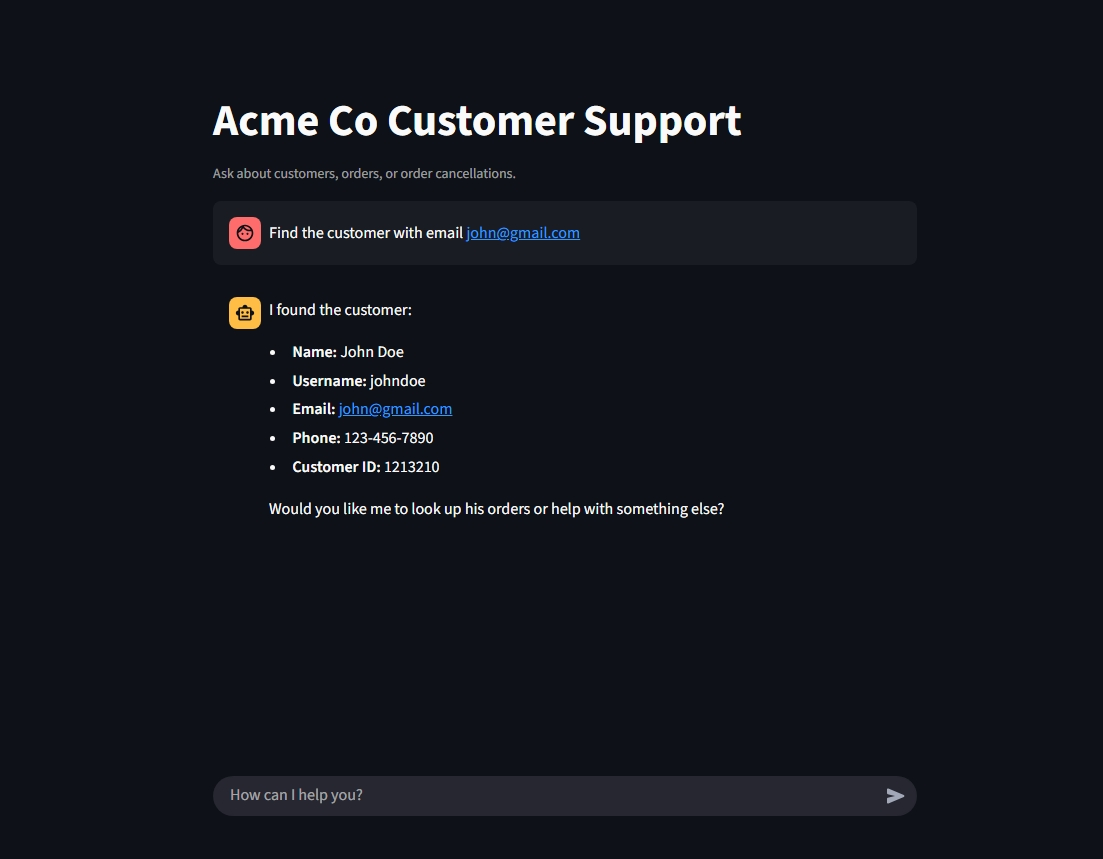

In [26]:
from IPython.display import Image
#Image(filename='Screenshot_Tool_Use_Streamlit.jpeg') 
Image(filename='Screenshot_Usage_Tool_Streamlit.jpeg') 

## Conclusion

This notebook demonstrated how tool use connects Claude's ability to select actions with functions implemented by the application.

Key principles:  

- Define tools with clear descriptions and input schemas.  
- Claude requests tools through structured tool_use responses.  
- The application executes the corresponding Python functions.  
- Results are returned using `tool_result`.  
- `stop_reason` helps control the iterative tool-use loop.  

The result is an **assistant that combines Claude's reasoning with application functionality to handle real-world tasks more effectively and reliably**.  

## Extra practice 

The best way to understand tool use is to extend  the fake database, yourself.  

### Challenge 1: Add a Shipping Tool

Add a new tool called: `get_shipping_status(order_id)` and return the shipping status of the order.



### Challenge 2 — Add a Refund Tool

Create: `process_refund(order_id)` 

Decide what business rules should apply.

For example:

- Can shipped orders be refunded?  
- Can cancelled orders be refunded?  
- What happens if the order does not exist?  
- What should the tool return when a refund is rejected?    
- Which orders are eligible?  
- What should happen when the order is not eligible?  
- What should the tool return?    

### Challenge 3 — Handle Multiple Tools

Create a request that requires more than one tool. For instance, give Claude a request such as:

`"Find Priya's orders and tell me which ones are still processing."`



### Challenge 4 — Handle Tool Errors

Test what happens when a tool cannot complete the requested operation.

Try cases such as:

- unknown customer  
- unknown order  
- invalid order ID  
- cancellation of an already shipped order  
- missing required information  